In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Make the experiment reproducible
np.random.seed(42)

# Generate 500 simulated observations
n = 500

time = np.random.uniform(0, 20, n)
initial_temp = np.random.uniform(20, 100, n)
ambient_temp = np.random.uniform(15, 35, n)
k = np.random.uniform(0.05, 0.30, n)

# Calculate temperature using the heat-transfer model
temperature = (
    ambient_temp
    + (initial_temp - ambient_temp) * np.exp(-k * time)
)

# Display a few observations
for i in range(5):
    print(
        f"Time: {time[i]:.2f} min, "
        f"Initial: {initial_temp[i]:.2f} °C, "
        f"Ambient: {ambient_temp[i]:.2f} °C, "
        f"k: {k[i]:.3f}, "
        f"Temperature: {temperature[i]:.2f} °C"
    )

Time: 7.49 min, Initial: 75.85 °C, Ambient: 18.70 °C, k: 0.180, Temperature: 33.57 °C
Time: 19.01 min, Initial: 62.89 °C, Ambient: 25.84 °C, k: 0.170, Temperature: 27.31 °C
Time: 14.64 min, Initial: 44.76 °C, Ambient: 32.46 °C, k: 0.056, Temperature: 37.85 °C
Time: 11.97 min, Initial: 85.10 °C, Ambient: 29.64 °C, k: 0.135, Temperature: 40.62 °C
Time: 3.12 min, Initial: 74.78 °C, Ambient: 31.13 °C, k: 0.145, Temperature: 58.89 °C


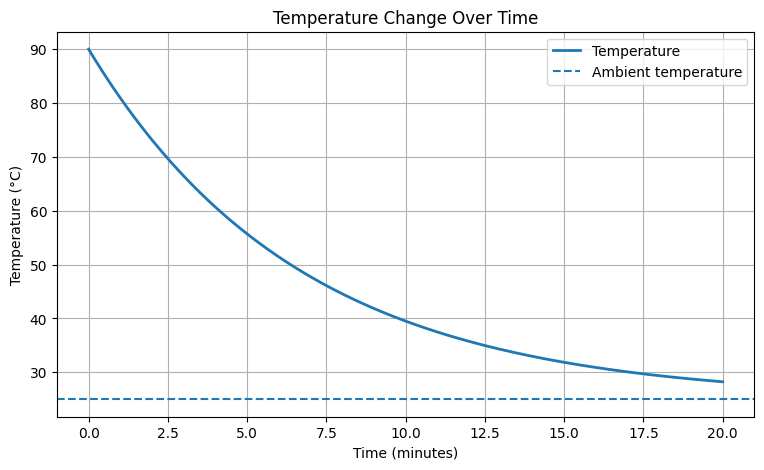

In [2]:
time_curve = np.linspace(0, 20, 200)

T0 = 90
Ta = 25
k_value = 0.15

T_curve = Ta + (T0 - Ta) * np.exp(-k_value * time_curve)

plt.figure(figsize=(9, 5))
plt.plot(time_curve, T_curve, label="Temperature", linewidth=2)
plt.axhline(Ta, linestyle="--", label="Ambient temperature")

plt.xlabel("Time (minutes)")
plt.ylabel("Temperature (°C)")
plt.title("Temperature Change Over Time")
plt.legend()
plt.grid(True)
plt.show()

In [3]:
import torch
import numpy as np

# Combine the four input variables
X = np.column_stack([
    time, initial_temp, ambient_temp, k
])

# Target temperature
y = temperature.reshape(-1, 1)

# Split into training (70%), validation (15%), test (15%)
np.random.seed(42)
indices = np.random.permutation(len(X))

train_end = int(0.70 * len(X))
val_end = int(0.85 * len(X))

train_idx = indices[:train_end]
val_idx = indices[train_end:val_end]
test_idx = indices[val_end:]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

# Normalize inputs using training data only
X_mean = X_train.mean(axis=0)
X_std = X_train.std(axis=0)

X_train = (X_train - X_mean) / X_std
X_val = (X_val - X_mean) / X_std
X_test = (X_test - X_mean) / X_std

# Convert NumPy arrays into PyTorch tensors
X_train = torch.tensor(X_train, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype=torch.float32)

X_val = torch.tensor(X_val, dtype=torch.float32)
y_val = torch.tensor(y_val, dtype=torch.float32)

X_test = torch.tensor(X_test, dtype=torch.float32)
y_test = torch.tensor(y_test, dtype=torch.float32)

print("Training inputs:", X_train.shape)
print("Training targets:", y_train.shape)
print("Validation inputs:", X_val.shape)
print("Test inputs:", X_test.shape)

Training inputs: torch.Size([350, 4])
Training targets: torch.Size([350, 1])
Validation inputs: torch.Size([75, 4])
Test inputs: torch.Size([75, 4])


Build the neural network

In [4]:
import torch
import torch.nn as nn

# Define the neural network
class TemperatureNN(nn.Module):
    def __init__(self):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(4, 32),  # 4 inputs -> 32 neurons
            nn.ReLU(),
            nn.Linear(32, 32), # 32 -> 32 neurons
            nn.ReLU(),
            nn.Linear(32, 1)   # 32 -> 1 temperature output
        )

    def forward(self, x):
        return self.network(x)

# Create the model
model = TemperatureNN()

print(model)

TemperatureNN(
  (network): Sequential(
    (0): Linear(in_features=4, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=32, bias=True)
    (3): ReLU()
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)


In [5]:
import copy

# Measure prediction error
criterion = nn.MSELoss()

# Update model parameters during training
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)

epochs = 1000
best_val_loss = float("inf")
best_weights = copy.deepcopy(model.state_dict())

train_losses = []
val_losses = []

for epoch in range(epochs):

    # Training phase
    model.train()
    predictions = model(X_train)
    loss = criterion(predictions, y_train)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    # Validation phase
    model.eval()
    with torch.no_grad():
        val_predictions = model(X_val)
        val_loss = criterion(val_predictions, y_val)

    train_losses.append(loss.item())
    val_losses.append(val_loss.item())

    # Keep the best model based on validation performance
    if val_loss.item() < best_val_loss:
        best_val_loss = val_loss.item()
        best_weights = copy.deepcopy(model.state_dict())

    if (epoch + 1) % 100 == 0:
        print(
            f"Epoch {epoch + 1:4d} | "
            f"Train MSE: {loss.item():.4f} | "
            f"Validation MSE: {val_loss.item():.4f}"
        )

# Restore the best model
model.load_state_dict(best_weights)

print("\nTraining complete!")
print(f"Best validation MSE: {best_val_loss:.4f}")

Epoch  100 | Train MSE: 19.1408 | Validation MSE: 27.8179
Epoch  200 | Train MSE: 14.8959 | Validation MSE: 23.5969
Epoch  300 | Train MSE: 12.7916 | Validation MSE: 21.6661
Epoch  400 | Train MSE: 11.1248 | Validation MSE: 19.8417
Epoch  500 | Train MSE: 9.6466 | Validation MSE: 18.1322
Epoch  600 | Train MSE: 7.1668 | Validation MSE: 14.3932
Epoch  700 | Train MSE: 3.2967 | Validation MSE: 7.8572
Epoch  800 | Train MSE: 2.1437 | Validation MSE: 6.1335
Epoch  900 | Train MSE: 1.7337 | Validation MSE: 5.1221
Epoch 1000 | Train MSE: 1.4111 | Validation MSE: 4.4033

Training complete!
Best validation MSE: 4.4033


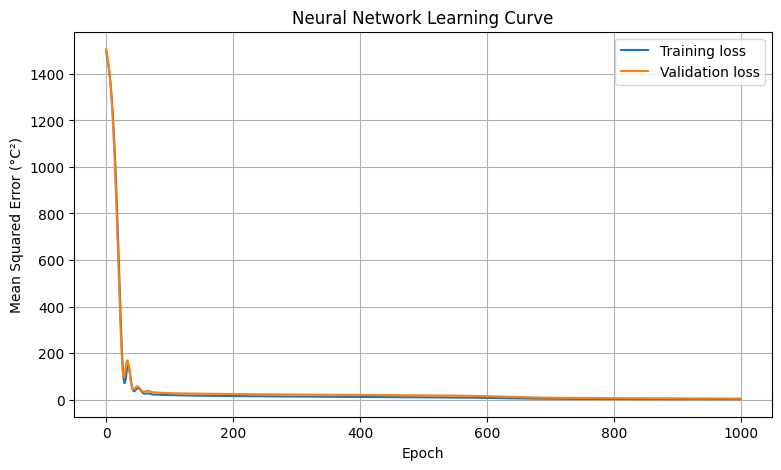

In [6]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Mean Squared Error (°C²)")
plt.title("Neural Network Learning Curve")
plt.legend()
plt.grid(True)
plt.show()

Calculate test performance

In [7]:
import numpy as np
import torch
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Evaluate on unseen test data
model.eval()

with torch.no_grad():
    predictions = model(X_test).cpu().numpy()

actual = y_test.cpu().numpy()

# Calculate performance metrics
mae = mean_absolute_error(actual, predictions)
rmse = np.sqrt(mean_squared_error(actual, predictions))
r2 = r2_score(actual, predictions)

print(f"Test MAE:  {mae:.4f} °C")
print(f"Test RMSE: {rmse:.4f} °C")
print(f"Test R²:   {r2:.4f}")

Test MAE:  1.0414 °C
Test RMSE: 1.5126 °C
Test R²:   0.9890


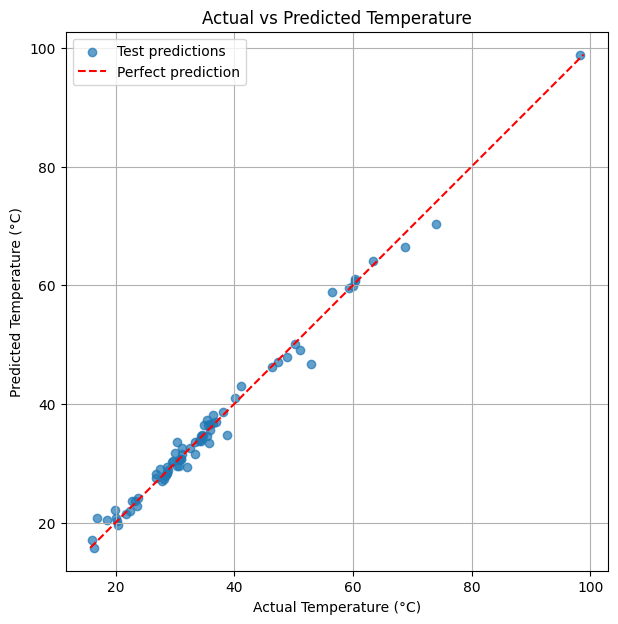

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 7))

plt.scatter(actual, predictions, alpha=0.7, label="Test predictions")

# Perfect predictions would lie on this line
low = min(actual.min(), predictions.min())
high = max(actual.max(), predictions.max())

plt.plot([low, high], [low, high], "r--", label="Perfect prediction")

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Actual vs Predicted Temperature")
plt.legend()
plt.grid(True)
plt.axis("equal")
plt.show()

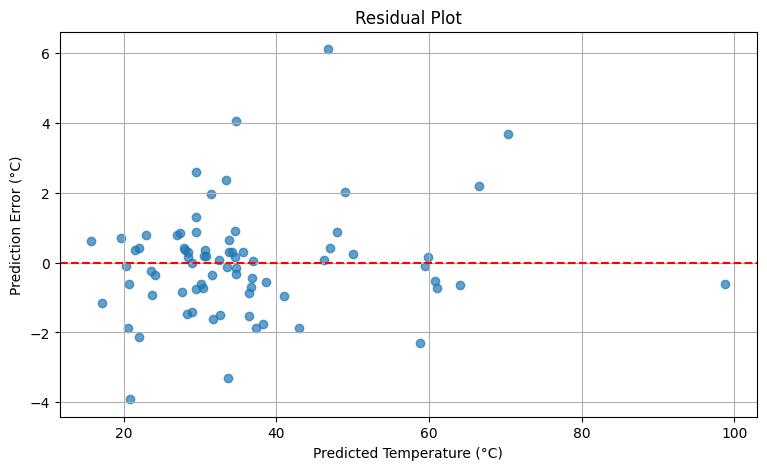

In [9]:
errors = actual.flatten() - predictions.flatten()

plt.figure(figsize=(9, 5))
plt.scatter(predictions.flatten(), errors, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")

plt.xlabel("Predicted Temperature (°C)")
plt.ylabel("Prediction Error (°C)")
plt.title("Residual Plot")
plt.grid(True)
plt.show()

Neural network MAE: 1.0414 °C
Physics equation MAE: 7.6e-07 °C


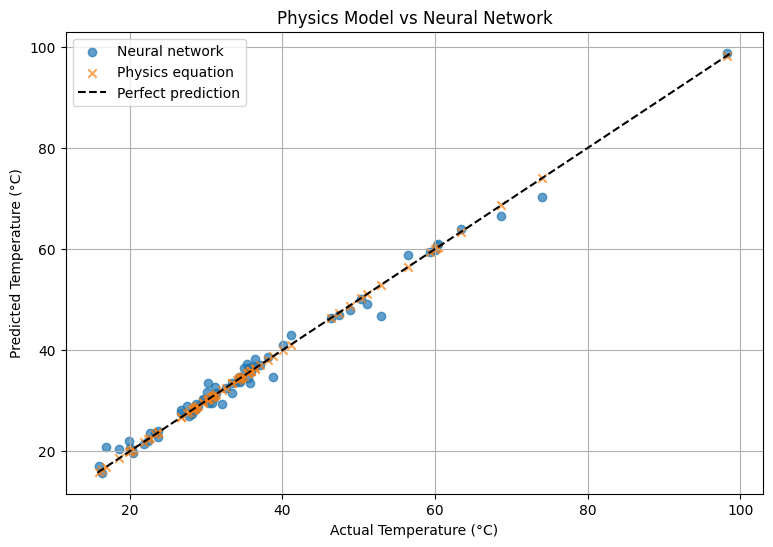

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import mean_absolute_error

# Recover the original, unnormalized test inputs
X_test_raw = X_test.cpu().numpy() * X_std + X_mean

# Extract test input variables
time_test = X_test_raw[:, 0]
T0_test = X_test_raw[:, 1]
Ta_test = X_test_raw[:, 2]
k_test = X_test_raw[:, 3]

# Predict using the original physics equation
physics_predictions = (
    Ta_test
    + (T0_test - Ta_test) * np.exp(-k_test * time_test)
)

# Predict using the trained neural network
model.eval()
with torch.no_grad():
    nn_predictions = model(X_test).cpu().numpy().flatten()

actual = y_test.cpu().numpy().flatten()

print("Neural network MAE:",
      round(mean_absolute_error(actual, nn_predictions), 4), "°C")

print("Physics equation MAE:",
      round(mean_absolute_error(actual, physics_predictions), 8), "°C")

# Plot both methods against actual temperatures
plt.figure(figsize=(9, 6))

plt.scatter(actual, nn_predictions,
            alpha=0.7, label="Neural network")

plt.scatter(actual, physics_predictions,
            alpha=0.7, label="Physics equation", marker="x")

low = min(actual.min(), nn_predictions.min(), physics_predictions.min())
high = max(actual.max(), nn_predictions.max(), physics_predictions.max())

plt.plot([low, high], [low, high], "k--",
         label="Perfect prediction")

plt.xlabel("Actual Temperature (°C)")
plt.ylabel("Predicted Temperature (°C)")
plt.title("Physics Model vs Neural Network")
plt.legend()
plt.grid(True)
plt.show()

In [11]:
import torch

checkpoint = {
    "model_state_dict": model.state_dict(),
    "x_mean": torch.tensor(X_mean, dtype=torch.float32),
    "x_std": torch.tensor(X_std, dtype=torch.float32),
    "input_features": [
        "time", "initial_temperature",
        "ambient_temperature", "k"
    ]
}

torch.save(checkpoint, "temperature_model.pth")

print("Model saved successfully!")

Model saved successfully!


In [12]:
from google.colab import files

files.download("temperature_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Robustness

Baseline MAE: 1.0414 °C
Noisy-input MAE: 1.1139 °C


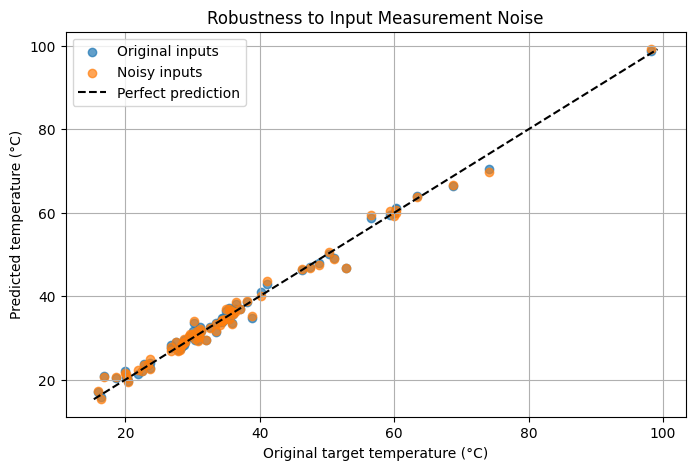

In [13]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Recover original test inputs
X_test_raw = X_test.cpu().numpy() * X_std + X_mean

# Baseline predictions
model.eval()
with torch.no_grad():
    baseline_pred = model(X_test).numpy().flatten()

actual = y_test.numpy().flatten()

# Add realistic illustrative measurement noise
rng = np.random.default_rng(42)
X_noisy = X_test_raw.copy()

# Columns: time, initial temperature, ambient temperature, k
X_noisy[:, 0] += rng.normal(0, 0.1, len(X_noisy))  # minutes
X_noisy[:, 1] += rng.normal(0, 0.5, len(X_noisy))   # °C
X_noisy[:, 2] += rng.normal(0, 0.5, len(X_noisy))   # °C

# Normalize using the original training-set statistics
X_noisy_norm = (X_noisy - X_mean) / X_std

X_noisy_tensor = torch.tensor(
    X_noisy_norm, dtype=torch.float32
)

with torch.no_grad():
    noisy_pred = model(X_noisy_tensor).numpy().flatten()

baseline_mae = mean_absolute_error(actual, baseline_pred)
noisy_mae = mean_absolute_error(actual, noisy_pred)

print(f"Baseline MAE: {baseline_mae:.4f} °C")
print(f"Noisy-input MAE: {noisy_mae:.4f} °C")

plt.figure(figsize=(8, 5))
plt.scatter(actual, baseline_pred, alpha=0.7, label="Original inputs")
plt.scatter(actual, noisy_pred, alpha=0.7, label="Noisy inputs")

low = min(actual.min(), baseline_pred.min(), noisy_pred.min())
high = max(actual.max(), baseline_pred.max(), noisy_pred.max())

plt.plot([low, high], [low, high], "k--", label="Perfect prediction")
plt.xlabel("Original target temperature (°C)")
plt.ylabel("Predicted temperature (°C)")
plt.title("Robustness to Input Measurement Noise")
plt.legend()
plt.grid(True)
plt.show()

In [14]:
import os
import torch

os.makedirs("models", exist_ok=True)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "x_mean": torch.tensor(X_mean, dtype=torch.float32),
    "x_std": torch.tensor(X_std, dtype=torch.float32),
    "input_features": [
        "time",
        "initial_temperature",
        "ambient_temperature",
        "k"
    ],
    "output_feature": "temperature"
}

torch.save(checkpoint, "models/temperature_model.pth")

print("Model checkpoint saved.")

Model checkpoint saved.


In [17]:
import os
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("results", exist_ok=True)

# Ensure predictions and actual are flat 1D arrays
flat_predictions = predictions.flatten()
flat_actual = actual.flatten()

# 1. Training and validation learning curve
plt.figure(figsize=(9, 5))
plt.plot(train_losses, label="Training loss")
plt.plot(val_losses, label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE (°C²)")
plt.title("Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("results/learning_curve.png", dpi=200)
plt.close()

# 2. Actual vs predicted
plt.figure(figsize=(7, 7))
plt.scatter(flat_actual, flat_predictions, alpha=0.7)

low = min(flat_actual.min(), flat_predictions.min())
high = max(flat_actual.max(), flat_predictions.max())
plt.plot([low, high], [low, high], "r--")

plt.xlabel("Actual temperature (°C)")
plt.ylabel("Predicted temperature (°C)")
plt.title("Actual vs Predicted Temperature")
plt.grid(True)
plt.axis("equal")
plt.tight_layout()
plt.savefig("results/actual_vs_predicted.png", dpi=200)
plt.close()

# 3. Residual plot
errors = flat_actual - flat_predictions

plt.figure(figsize=(9, 5))
plt.scatter(flat_predictions, errors, alpha=0.7)
plt.axhline(0, color="red", linestyle="--")
plt.xlabel("Predicted temperature (°C)")
plt.ylabel("Actual - predicted (°C)")
plt.title("Prediction Residuals")
plt.grid(True)
plt.tight_layout()
plt.savefig("results/residual_plot.png", dpi=200)
plt.close()

# 4. Robustness comparison
plt.figure(figsize=(8, 5))
plt.bar(
    ["Baseline", "Noisy inputs"],
    [baseline_mae, noisy_mae]
)
plt.ylabel("MAE (°C)")
plt.title("Sensitivity to Input Noise")
plt.tight_layout()
plt.savefig("results/noise_robustness.png", dpi=200)
plt.close()

print("All four plots saved in the results folder.")

All four plots saved in the results folder.
